# Лабораторная работа №1. Пайплайны обработки данных на основе LangChain и LLM

Прототип интеллектуального интерфейса к каталогу товаров: пользователь пишет запрос на естественном языке (например, «Покажи самые дешевые ноутбуки до 80 тысяч рублей»), LLM превращает его в структурированные параметры поиска, а обычная программа проверяет их и ищет товары в SQLite. Стадии пайплайна:
1. Получение запроса пользователя
2. Формирование промпта с помощью LangChain
3. Вызов LLM
4. Парсинг и валидация ответа по схеме Pydantic
5. Повторная генерация в случае ошибки парсинга (retry)
6. Передача валидных параметров в функцию поиска по SQLite
7. Вывод результатов поиска или сообщения об отсутствии подходящих товаров

Каждая стадия пишется в журнал. LLM не формирует и не выполняет SQL** - она только интерпретирует текст, SQL собирает обычный код.

**Цель**: научиться строить простейшего агента в виде пайплайна — LLM возвращает параметры в согласованном формате (структурированный ответ или вызов инструмента), а программа проверяет их и выполняет действие; обработать ошибки разбора повторными попытками, вести журнал выполнения и хранить состояние диалога вне модели.

Код, который нужен и ноутбуку, и итоговой программе `app.py`, вынесен в `utils.py` (схема, промпты, поиск, журнал, пайплайн с retry), база создаётся в `init_db.py`

In [ ]:
import inspect
import json
import os
import re
import sqlite3
import time
import warnings
from getpass import getpass

import httpx
import pandas as pd
import matplotlib.pyplot as plt
from openai import OpenAI
from pydantic import ValidationError
from langchain_core.exceptions import OutputParserException
from langchain_core.language_models.fake_chat_models import FakeListChatModel, FakeMessagesListChatModel
from langchain_core.messages import AIMessage, HumanMessage
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langchain_core.runnables import RunnableLambda
from langchain_core.utils.function_calling import convert_to_openai_tool

from init_db import DB_PATH, init_db
from utils import (BASE_URL, JSON_ONLY, MODEL_NAME, RULES, Journal, ProductQuery, ask, build_pipeline, build_sql,
                   first_error, fmt_items, fmt_price, get_llm, make_parse_prompt, parser, q_short, run_search,
                   search_products, search_products_tool, server_available)

warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', 200)

In [35]:
# токен в .env
if not os.getenv('LLM_API_KEY'):
  os.environ['LLM_API_KEY'] = getpass('токен: ')
print(f'сервер {BASE_URL}, модель {MODEL_NAME}, доступен: {server_available()}')

сервер http://10.32.2.11:35000/v1, модель qwen3.8-27b, доступен: True


In [36]:
init_db()
llm = get_llm() # режим размышления выключен

# ожидаемые параметры для проверок
PQ = lambda c, p=None, s='price_asc': ProductQuery(category=c, max_price=p, sort_by=s)

## Сервер и модель

In [37]:
def raw_chat(content, **extra):
  body = dict(model=MODEL_NAME, messages=[{'role': 'user', 'content': content}], max_tokens=512, temperature=0.7, **extra)
  t0 = time.perf_counter()
  r = httpx.post(f'{BASE_URL}/chat/completions', json=body, timeout=180,
                 headers={'Authorization': f"Bearer {os.environ['LLM_API_KEY']}"})
  r.raise_for_status()
  return r.json(), time.perf_counter() - t0

## Часть 1. Базовая цепочка LangChain

In [38]:
cat_prompt = ChatPromptTemplate.from_messages([
  ('system', 'Ты консультант интернет-магазина электроники. Определи, к какой категории товаров относится '
             'запрос пользователя (например: ноутбуки, смартфоны, планшеты или другое). '
             'Ответь одним коротким предложением на языке: {language}.'),
  ('human', '{query}')
])
cat_chain = cat_prompt | llm | StrOutputParser()

inp = dict(query='Покажи самые дешевые ноутбуки до 80 тысяч рублей', language='русский')
pv = cat_prompt.invoke(inp)
raw = llm.invoke(pv) # прямой вызов модели
res = cat_chain.invoke(inp) # вызов цепочки

print('переменные промпта:', cat_prompt.input_variables)
print(f'prompt.invoke -> {type(pv).__name__}: {[type(m).__name__ for m in pv.to_messages()]}')
print(f'llm.invoke -> {type(raw).__name__}')
print(f'content: {raw.content!r}')
print(f'usage_metadata: {raw.usage_metadata}')
print(f'chain.invoke -> {type(res).__name__}, isinstance(str) = {isinstance(res, str)}')
print(f'{res!r}')

переменные промпта: ['language', 'query']
prompt.invoke -> ChatPromptValue: ['SystemMessage', 'HumanMessage']
llm.invoke -> AIMessage
content: 'Запрос относится к категории ноутбуков.'
usage_metadata: {'input_tokens': 82, 'output_tokens': 9, 'total_tokens': 91, 'input_token_details': {}, 'output_token_details': {}}
chain.invoke -> TextAccessor, isinstance(str) = True
'Запрос относится к категории ноутбуков.'


In [39]:
batch_inp = [
  dict(query='Найди ноутбуки дешевле 70 000 рублей', language='русский'),
  dict(query='Покажи самые дорогие смартфоны', language='английский'),
  dict(query='Хочу посмотреть планшеты', language='русский'),
  dict(query='Найди холодильники', language='русский'),
  dict(query='Нужен телефон с хорошей камерой', language='немецкий')
]
t0 = time.perf_counter()
answers = cat_chain.batch(batch_inp)
print(f'batch из 5 запросов: {time.perf_counter() - t0:.1f} с')
pd.DataFrame(batch_inp).assign(answer=answers)

batch из 5 запросов: 60.5 с


,query,language,answer
0,Найди ноутбуки дешевле 70 000 рублей,русский,Запрос относится к категории ноутбуки.
1,Покажи самые дорогие смартфоны,английский,Your request belongs to the smartphones category.
2,Хочу посмотреть планшеты,русский,Ваш запрос относится к категории планшетов.
3,Найди холодильники,русский,Запрос относится к категории крупной бытовой техники.
4,Нужен телефон с хорошей камерой,немецкий,Sie suchen ein Smartphone.


- промпт после `invoke` - это `ChatPromptValue`, т.е. уже готовый список сообщений System + Human с подставленными переменными
- прямой вызов модели возвращает `AIMessage`: кроме текста там `response_metadata` и `usage_metadata` (82 токена на входе, 9 на выходе). Цепочка со `StrOutputParser` отдаёт только строку `content` (в этой версии langchain это `TextAccessor`, но это наследник `str`, так что работаем как со строкой)
- переменная `language` работает: на английский и немецкий запросы модель ответила на нужном языке
- для холодильников модель придумала свою категорию "крупная бытовая техника", а одну и ту же мысль каждый раз формулирует по-разному ("категории ноутбуков", "категории ноутбуки", "Sie suchen ein Smartphone"). Такой текст программа надёжно не разберёт, поэтому дальше нужен структурированный ответ
- batch из 5 запросов занял 60.5 с, хотя один вызов идёт ~0.4 с — скорее всего, была очередь на общем сервере, так что по этому замеру скорость batch не оценить

## Часть 2. Structured Output и Pydantic

### Схема ProductQuery

In [40]:
print(inspect.getsource(ProductQuery))
print('по умолчанию:', ProductQuery(category='tablet'))

class ProductQuery(BaseModel):
  '''Параметры поиска товаров в каталоге магазина электроники'''
  # лишние поля запрещаем: иначе "price" вместо "max_price" молча превратится в цену по умолчанию
  model_config = ConfigDict(extra='forbid')

  category: Literal['laptop', 'smartphone', 'tablet', 'other'] = Field(
      description='Категория товара: laptop - ноутбуки, smartphone - смартфоны/телефоны, tablet - планшеты. '
                  'Если товар не из этих категорий (холодильник, наушники, телевизор и т.п.), то other.')
  max_price: Optional[int] = Field(
      default=None, ge=0,
      description='Верхняя граница цены в рублях, целое число ("до 50 тысяч" -> 50000). '
                  'null, если пользователь не ограничил цену.')
  sort_by: Literal['price_asc', 'price_desc'] = Field(
      default='price_asc',
      description='Сортировка по цене: price_asc - сначала дешёвые (по умолчанию), price_desc - сначала дорогие.')

по умолчанию: category='tablet' max_price=None sort_by='pri

* `category` - обязательное поле, `Literal` из четырёх значений, неподдерживаемые товары -> `other` (это сказано в описании поля, его видит модель)
* `max_price` - `Optional[int]` с `ge=0`, по умолчанию `None` = цена не ограничена
* `sort_by` - `Literal`, по умолчанию `price_asc`
* `extra='forbid'` добавила сама: без него, если модель напишет `"price"` вместо `"max_price"`, Pydantic молча проигнорирует ключ и цена станет `None`, а так будет ошибка и повторная генерация

### Инструкции формата
`PydanticOutputParser(pydantic_object=ProductQuery).get_format_instructions()` вставляем в **системный** промпт через `partial`. в инструкциях JSON-схема с фигурными скобками, и если вписать её прямо в шаблон, то LangChain примет скобки за переменные. Кроме инструкций в системном промпте правила: какие бывают категории, что 50к = 50000, дешевле X = `max_price`, самые дорогие = `price_desc`

In [41]:
parse_prompt = make_parse_prompt()
print(parse_prompt.invoke({'query': '...'}).to_messages()[0].content)

Ты - модуль разбора запросов для интернет-магазина электроники.
Твоя задача - превратить запрос пользователя на естественном языке в параметры поиска.
В каталоге есть только три категории: ноутбуки (laptop), смартфоны (smartphone) и планшеты (tablet).
Правила:
- если пользователь ищет что-то другое (холодильник, наушники, телевизор и т.д.), то category = "other";
- цену переводи в рубли целым числом: "50 тысяч", "50к", "50 000 руб." -> 50000;
- "дешевле X", "до X", "не дороже X" означает max_price = X;
- если цена не названа, max_price = null;
- "самые дорогие", "сначала дорогие" -> sort_by = "price_desc", во всех остальных случаях "price_asc".
Отвечай ТОЛЬКО JSON-объектом, без пояснений и без markdown.

The output should be formatted as a JSON instance that conforms to the JSON schema below.

As an example, for the schema {"properties": {"foo": {"title": "Foo", "description": "a list of strings", "type": "array", "items": {"type": "string"}}}, "required": ["foo"]}
the object {"foo": [

In [42]:
chain = parse_prompt | llm | parser

q = chain.invoke({'query': 'Покажи самые дешевые ноутбуки до 80 тысяч рублей'})
print(repr(q))
print(f'тип: {type(q).__name__}, isinstance ProductQuery: {isinstance(q, ProductQuery)}')
print('JSON:', q.model_dump_json())

ProductQuery(category='laptop', max_price=80000, sort_by='price_asc')
тип: ProductQuery, isinstance ProductQuery: True
JSON: {"category":"laptop","max_price":80000,"sort_by":"price_asc"}


### Тестирование

5 запросов из задания + 2 своих неоднозначных. Для каждого сохраняем текст, JSON и проверку полей (таблица + файл `tests_2_3.json`)

In [43]:
TESTS_23 = [
  ('Найди ноутбуки дешевле 70 000 рублей', 'категория и числовое ограничение', PQ('laptop', 70000)),
  ('Покажи самые дорогие смартфоны', 'сортировка по убыванию цены', PQ('smartphone', s='price_desc')),
  ('Хочу посмотреть планшеты', 'нет ограничения цены', PQ('tablet')),
  ('Покажи ноутбуки до 50 тысяч', 'нормализация числа', PQ('laptop', 50000)),
  ('Найди холодильники', 'неизвестная категория other', PQ('other'))
]
AMBIGUOUS = [
  'Нужен ноут или планшет для учёбы, бюджет где-то 60к',
  'Покажи что-нибудь от Apple подороже'
]

def check_fields(q, exp):
  return {f: ("+ " if q is not None and getattr(q, f) == getattr(exp, f) else '- ') + str(getattr(q, f, 'х'))
          for f in ProductQuery.model_fields}

In [44]:
rows = []
for text, what, exp in TESTS_23 + [(t, 'неоднозначный', None) for t in AMBIGUOUS]:
  try:
    q = chain.invoke({'query': text})
    js = q.model_dump_json()
  except OutputParserException as e:
    q, js = None, f'ошибка: {type(e.__cause__).__name__}'
  row = dict(query=text, check=what, json=js)
  if exp is not None:
    row.update(check_fields(q, exp), ok=q == exp)
  rows.append(row)

tests_23 = pd.DataFrame(rows).fillna('-')
tests_23.to_json('tests_2_3.json', orient='records', force_ascii=False, indent=2)
print(f"прошло {(tests_23['ok'] == True).sum()} из {len(TESTS_23)}")
tests_23

прошло 5 из 5


,query,check,json,category,max_price,sort_by,ok
0,Найди ноутбуки дешевле 70 000 рублей,категория и числовое ограничение,"{""category"":""laptop"",""max_price"":70000,""sort_by"":""price_asc""}",+ laptop,+ 70000,+ price_asc,True
1,Покажи самые дорогие смартфоны,сортировка по убыванию цены,"{""category"":""smartphone"",""max_price"":null,""sort_by"":""price_desc""}",+ smartphone,+ None,+ price_desc,True
2,Хочу посмотреть планшеты,нет ограничения цены,"{""category"":""tablet"",""max_price"":null,""sort_by"":""price_asc""}",+ tablet,+ None,+ price_asc,True
3,Покажи ноутбуки до 50 тысяч,нормализация числа,"{""category"":""laptop"",""max_price"":50000,""sort_by"":""price_asc""}",+ laptop,+ 50000,+ price_asc,True
4,Найди холодильники,неизвестная категория other,"{""category"":""other"",""max_price"":null,""sort_by"":""price_asc""}",+ other,+ None,+ price_asc,True
5,"Нужен ноут или планшет для учёбы, бюджет где-то 60к",неоднозначный,"{""category"":""laptop"",""max_price"":60000,""sort_by"":""price_asc""}",-,-,-,-
6,Покажи что-нибудь от Apple подороже,неоднозначный,"{""category"":""other"",""max_price"":null,""sort_by"":""price_desc""}",-,-,-,-


**Неоднозначные запросы**
- "Нужен ноут или планшет для учёбы, бюджет где-то 60к" -> `laptop, 60000, price_asc`. В схеме только одна категория, модель взяла первую названную (ноутбук), планшеты потерялись. "Где-то 60к" стало жёстким потолком `max_price=60000`, поэтому найдётся только Lenovo за 54 990, а ASUS за 61 490, который пользователь скорее всего тоже бы посмотрел, отсекается
- "Покажи что-нибудь от Apple подороже" -> `other, null, price_desc`. Бренда в схеме нет, и модель ушла в `other` — программа ответит "такие товары не продаются", **хотя в базе 5 товаров Apple во всех трёх категориях** (iPad Pro 13 M4 149 990, iPhone 16 Pro Max 139 990, MacBook Air 13 M3 124 990, iPhone 15 79 990, iPad Air 11 M2 69 990). Т.е. это не просто неоднозначность, а неправильный ответ для пользователя. "Подороже" модель поняла как сортировку `price_desc`
- т.е. что не влезает в схему, то теряется. Чтобы такое обрабатывать, в схеме нужны список категорий, бренд (в SQL - фильтр `name LIKE ?`) и мягкая граница цены

### Режим размышления

Те же два неоднозначных запроса, цепочка с `enable_thinking=False` и `True`. Сравниваем параметры, время, число выходных токенов и что приходит в `content`. Для режима размышления `temperature=0.6` (иначе может зациклиться)

In [45]:
def strip_think(text):
  '''если сервер не вырезает рассуждение, оно приходит прямо в content в тегах <think>'''
  return re.sub(r'<think>.*?</think>', '', text, flags=re.S).strip()

In [46]:
think_rows, THINK_MSGS = [], {}
for text in AMBIGUOUS:
  for thinking in [False, True]:
    t0 = time.perf_counter()
    msg = (parse_prompt | get_llm(thinking=thinking, max_tokens=8000)).invoke({'query': text})
    dt = time.perf_counter() - t0
    THINK_MSGS[(text, thinking)] = msg
    has_think = '<think>' in msg.content

    q, parsed = None, 'ок'
    try:
      q = parser.invoke(msg)
    except OutputParserException as e:
      parsed = f'падает ({type(e.__cause__).__name__})'
      if has_think:
        try:
          q = parser.parse(strip_think(msg.content))
          parsed += ', после вырезания <think> ок'
        except OutputParserException:
          pass

    u = msg.usage_metadata or {}
    think_rows.append(dict(query=text, thinking=thinking, params=q_short(q), parser=parsed, time_s=dt,
                           input_tokens=u.get('input_tokens'), output_tokens=u.get('output_tokens'),
                           reasoning_tokens=(u.get('output_token_details') or {}).get('reasoning', '-'),
                           think_in_content=has_think, content=msg.content[:150]))

think_tab = pd.DataFrame(think_rows)
think_tab.style.format({'time_s': '{:.2f}'})

,query,thinking,params,parser,time_s,input_tokens,output_tokens,reasoning_tokens,think_in_content,content
0,"Нужен ноут или планшет для учёбы, бюджет где-то 60к",False,"laptop, 60000, price_asc",ок,0.37,655,36,-,False,"{ ""category"": ""laptop"", ""max_price"": 60000, ""sort_by"": ""price_asc"" }"
1,"Нужен ноут или планшет для учёбы, бюджет где-то 60к",True,"laptop, 60000, price_asc",ок,3.10,691,273,-,False,"{""category"":""laptop"",""max_price"":60000,""sort_by"":""price_asc""}"
2,Покажи что-нибудь от Apple подороже,False,"other, None, price_desc",ок,0.34,647,30,-,False,"{ ""category"": ""other"", ""max_price"": null, ""sort_by"": ""price_desc"" }"
3,Покажи что-нибудь от Apple подороже,True,"other, None, price_desc",ок,4.12,683,383,-,False,"{""category"": ""other"", ""max_price"": null, ""sort_by"": ""price_desc""}"


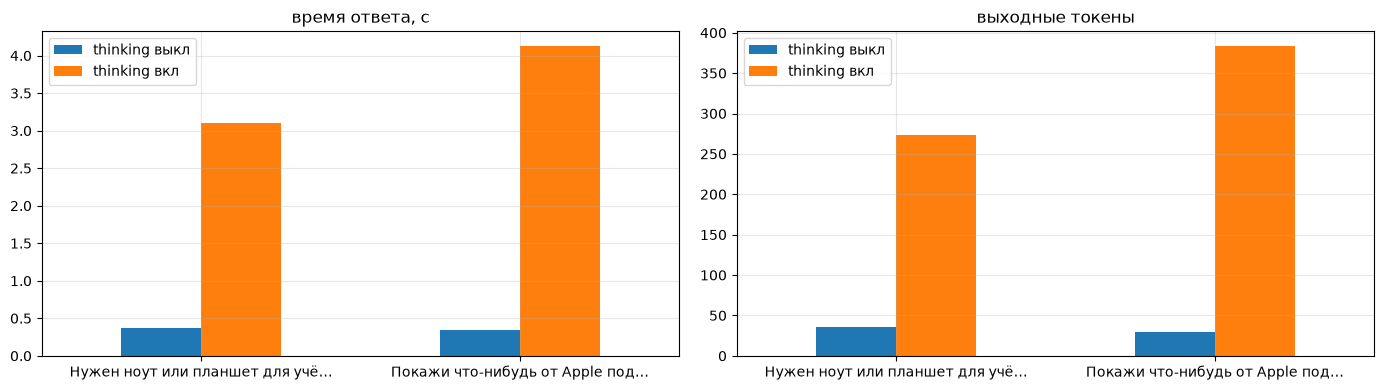

с размышлением время больше в 10.1 раз, выходных токенов больше в 9.9 раз
параметры совпали в 2 из 2 запросов


In [47]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col, title in zip(axes, ['time_s', 'output_tokens'], ['время ответа, с', 'выходные токены']):
  tab = think_tab.pivot(index='query', columns='thinking', values=col).loc[AMBIGUOUS]
  tab.plot.bar(ax=ax, rot=0, color=['tab:blue', 'tab:orange'])
  ax.set_title(title)
  ax.set_xlabel('')
  ax.set_xticklabels([t[:30] + '…' for t in tab.index])
  ax.grid(alpha=0.3)
  ax.legend(['thinking выкл', 'thinking вкл'])
plt.tight_layout()
plt.show()

off, on = think_tab[~think_tab['thinking']], think_tab[think_tab['thinking']]
print(f"с размышлением время больше в {on['time_s'].sum() / off['time_s'].sum():.1f} раз, "
      f"выходных токенов больше в {on['output_tokens'].sum() / off['output_tokens'].sum():.1f} раз")
print(f"параметры совпали в {(off['params'].values == on['params'].values).sum()} из {len(off)} запросов")

In [48]:
# ChatOpenAI поле reasoning_content выбрасывает, поэтому смотрим сырой ответ сервера через openai-клиент
client = OpenAI(base_url=BASE_URL, api_key=os.getenv('LLM_API_KEY'))
msgs = [{'role': 'system' if m.type == 'system' else 'user', 'content': m.content}
        for m in parse_prompt.invoke({'query': AMBIGUOUS[0]}).to_messages()]
resp = client.chat.completions.create(model=MODEL_NAME, messages=msgs, temperature=0.6, top_p=0.95, max_tokens=8000,
                                      extra_body={'chat_template_kwargs': {'enable_thinking': True}})
m = resp.choices[0].message
extra = m.model_extra or {}
reasoning = extra.get('reasoning_content') or extra.get('reasoning') or ''

print('поля message:', list(m.model_dump(exclude_none=True)))
print('content:', repr((m.content or '')[:300]))
print(f'рассуждение: {len(reasoning)} символов')
print(reasoning[:600])
print('\nusage:', resp.usage)
print('ключи additional_kwargs в LangChain:', list(THINK_MSGS[(AMBIGUOUS[0], True)].additional_kwargs))

поля message: ['content', 'role', 'reasoning_content', 'provider_specific_fields']
content: '\n\n{"category":"laptop","max_price":60000,"sort_by":"price_asc"}'
рассуждение: 1317 символов
Нужно ответить только JSON. Запрос: "Нужен ноут или планшет для учёбы, бюджет где-то 60к". Категория: пользователь хочет ноут или планшет, т.е. не одна конкретная категория из enum? В схеме category только один из laptop, smartphone, tablet, other. Правила: в каталоге есть три категории. Если пользователь ищет что-то другое -> other. Здесь ищет ноут или планшет. Нужно выбрать? Возможно, поскольку запрос содержит несколько категорий, но schema требует один. Нужно как-то решить. В правилах нет "multiple categories". Вероятно, выбрать ближайшую? "ноут или планшет" - оба есть. Но category enum не 

usage: CompletionUsage(completion_tokens=388, prompt_tokens=691, total_tokens=1079, completion_tokens_details=None, prompt_tokens_details=None)
ключи additional_kwargs в LangChain: ['refusal']


- на этом сервере рассуждение отделено: `<think>` в `content` не встретился ни разу, а в сыром ответе есть отдельное поле `reasoning_content` (1317 символов). В `content` остаётся только JSON (с `\n\n` в начале), и `PydanticOutputParser` с ним справляется, `strip_think` не понадобился. Если бы сервер рассуждение не отделял, оно пришло бы прямо в `content`, и парсер упал бы с `JSONDecodeError`
- `ChatOpenAI` поле `reasoning_content` выбрасывает: в `additional_kwargs` только `refusal`, рассуждение видно только через сырой `openai`-клиент
- в рассуждении видно, что модель сама заметила проблему ("ноут или планшет", а схема требует одну категорию), но в итоге выбрала то же, что и без размышления — `laptop, 60000`
- с размышлением время больше в 10.1 раз (3.1-4.1 с против 0.34-0.37 с), выходных токенов больше в 9.9 раз (273-383 против 30-36). Отдельно число reasoning-токенов сервер не отдаёт, они входят в выходные. Параметры на обоих запросах совпали, т.е. для извлечения трёх полей размышление ничего не дало — поэтому во всех остальных заданиях оно выключено
- **почему рассуждение не должно попадать в разбираемый текст**: это черновик на естественном языке, там бывают и фигурные скобки, и промежуточные варианты, которые модель потом отбросила (в нашем рассуждении она перебирает категории). Парсер мог бы упасть или, что хуже, вытащить не тот JSON. Разбирать надо только финальный ответ

## Часть 3. Вызов классического программного обеспечения

### Каталог товаров

Таблица `products(id, name, category, price)` создаётся скриптом `init_db.py`: 7 ноутбуков, 7 смартфонов, 5 планшетов. Цены подобраны так, чтобы часть запросов давала пустой результат (ноутбуков дешевле 54 990 нет, смартфонов дешевле 18 990 тоже)

In [49]:
conn = sqlite3.connect(DB_PATH)
catalog = pd.read_sql('SELECT * FROM products', conn)
conn.close()
print(catalog.groupby('category')['price'].agg(['count', 'min', 'max']))
catalog

            count    min     max
category                        
laptop          7  54990  159990
smartphone      7  18990  139990
tablet          5  14990  149990


,id,name,category,price
0,1,Lenovo IdeaPad Slim 3 15,laptop,54990
1,2,ASUS Vivobook 16,laptop,61490
2,3,Acer Aspire 5,laptop,67990
3,4,HUAWEI MateBook D 16,laptop,74990
4,5,HONOR MagicBook X16,laptop,79990
5,6,Apple MacBook Air 13 M3,laptop,124990
6,7,ASUS ROG Strix G16,laptop,159990
7,8,Xiaomi Redmi Note 13,smartphone,18990
8,9,POCO X6 Pro,smartphone,27990
9,10,realme 12 Pro+,smartphone,32490


### Программный поиск

`search_products(q: ProductQuery)` из `utils.py`:
* SQL собирается из фиксированных кусков: `WHERE category = ?`, если есть цена — `AND price <= ?`
* значения (категория, цена) передаются только параметрами `?`, а не подставляются в строку
* направление сортировки параметром не передать, поэтому оно берётся из белого списка `{'price_asc': 'ASC', 'price_desc': 'DESC'}`
* **category = other**: в базу не идём вообще (иначе пришлось бы показать весь каталог, а человек искал холодильник), функция бросает `UnsupportedCategoryError`, а пайплайн показывает «Такие товары в каталоге не продаются. Есть только ноутбуки, смартфоны и планшеты.»

In [50]:
print(inspect.getsource(build_sql))

def build_sql(q):
  '''SQL из разрешённых полей, значения пользователя только через параметры ?'''
  sql = 'SELECT id, name, category, price FROM products WHERE category = ?'
  params = [q.category]
  if q.max_price is not None:
    sql += ' AND price <= ?'
    params.append(q.max_price)
  sql += f' ORDER BY price {ORDER_SQL[q.sort_by]}, id'
  return sql, params



In [51]:
CASES_32 = [PQ('laptop', 70000), PQ('laptop', 50000), PQ('smartphone', s='price_desc'), PQ('tablet', 15000),
            PQ('tablet', 100000, 'price_desc'), PQ('other')]
rows = []
for q in CASES_32:
  res = run_search(q)
  sql, params = build_sql(q) if q.category != 'other' else ('-', [])
  rows.append(dict(query=q_short(q), sql=sql, params=params, status=res['status'],
                   found=fmt_items(res['items']) or res['message']))
pd.DataFrame(rows)

,query,sql,params,status,found
0,"laptop, 70000, price_asc","SELECT id, name, category, price FROM products WHERE category = ? AND price <= ? ORDER BY price ASC, id","[laptop, 70000]",ok,Lenovo IdeaPad Slim 3 15 — 54 990 ₽; ASUS Vivobook 16 — 61 490 ₽; Acer Aspire 5 — 67 990 ₽
1,"laptop, 50000, price_asc","SELECT id, name, category, price FROM products WHERE category = ? AND price <= ? ORDER BY price ASC, id","[laptop, 50000]",empty,Подходящих товаров не найдено.
2,"smartphone, None, price_desc","SELECT id, name, category, price FROM products WHERE category = ? ORDER BY price DESC, id",[smartphone],ok,Apple iPhone 16 Pro Max — 139 990 ₽; Samsung Galaxy S24 Ultra — 119 990 ₽; Apple iPhone 15 — 79 990 ₽; Samsung Galaxy A55 — 34 990 ₽; realme 12 Pro+ — 32 490 ₽; POCO X6 Pro — 27 990 ₽; Xiaomi Redm...
3,"tablet, 15000, price_asc","SELECT id, name, category, price FROM products WHERE category = ? AND price <= ? ORDER BY price ASC, id","[tablet, 15000]",ok,Xiaomi Redmi Pad SE — 14 990 ₽
4,"tablet, 100000, price_desc","SELECT id, name, category, price FROM products WHERE category = ? AND price <= ? ORDER BY price DESC, id","[tablet, 100000]",ok,Apple iPad Air 11 M2 — 69 990 ₽; Samsung Galaxy Tab S9 FE — 39 990 ₽; HUAWEI MatePad 11.5 — 29 990 ₽; Xiaomi Redmi Pad SE — 14 990 ₽
5,"other, None, price_asc",-,[],unsupported,"Такие товары в каталоге не продаются. Есть только ноутбуки, смартфоны и планшеты."


In [52]:
# попытка подсунуть SQL через категорию
try:
  ProductQuery(category="laptop' OR 1=1; DROP TABLE products; --")
except ValidationError as e:
  print('ValidationError:', first_error(e))

ValidationError: category: Input should be 'laptop', 'smartphone', 'tablet' or 'other' (получено "laptop' OR 1=1; DROP TABLE products; --")


### Объединение компонентов

Обычная функция поиска встраивается в LCEL через `RunnableLambda`: `parse_prompt | llm | parser | RunnableLambda(run_search)` — на выходе уже найденные товары. Корректность = параметры совпали с ожидаемыми (товары по ним достаются из базы детерминированно)

In [53]:
search_step = RunnableLambda(run_search, name='search_products')
pipeline_33 = parse_prompt | llm | parser | search_step

TESTS_33 = [
  ('Найди ноутбуки дешевле 70 000 рублей', PQ('laptop', 70000)),
  ('Покажи самые дорогие смартфоны', PQ('smartphone', s='price_desc')),
  ('Хочу посмотреть планшеты', PQ('tablet')),
  ('Покажи ноутбуки до 50 тысяч', PQ('laptop', 50000)),
  ('Найди холодильники', PQ('other')),
  ('Покажи самые дешевые ноутбуки до 80 тысяч рублей', PQ('laptop', 80000)),
  ('Смартфон не дороже 30к', PQ('smartphone', 30000)),
  ('Какие есть планшеты до 15 тысяч?', PQ('tablet', 15000)),
  ('Самые дорогие планшеты, но не дороже 100 000', PQ('tablet', 100000, 'price_desc')),
  ('Нужны наушники до 10 тысяч', PQ('other', 10000)),
  ('Смартфоны дешевле 15000 рублей', PQ('smartphone', 15000)),
  ('Покажи айфоны', PQ('smartphone'))
]

rows = []
for text, exp in TESTS_33:
  try:
    res = pipeline_33.invoke({'query': text})
    q, found = res['query'], fmt_items(res['items']) or res['message']
  except OutputParserException as e:
    q, found = None, f'ошибка разбора: {type(e.__cause__).__name__}'
  rows.append(dict(query=text, params=q_short(q), found=found,
                   correct='+' if q == exp else f'х ожидалось {q_short(exp)}'))

tab_33 = pd.DataFrame(rows)
print(f"корректно: {(tab_33['correct'] == '+').sum()} из {len(tab_33)}")
tab_33

корректно: 12 из 12


,query,params,found,correct
0,Найди ноутбуки дешевле 70 000 рублей,"laptop, 70000, price_asc",Lenovo IdeaPad Slim 3 15 — 54 990 ₽; ASUS Vivobook 16 — 61 490 ₽; Acer Aspire 5 — 67 990 ₽,+
1,Покажи самые дорогие смартфоны,"smartphone, None, price_desc",Apple iPhone 16 Pro Max — 139 990 ₽; Samsung Galaxy S24 Ultra — 119 990 ₽; Apple iPhone 15 — 79 990 ₽; Samsung Galaxy A55 — 34 990 ₽; realme 12 Pro+ — 32 490 ₽; POCO X6 Pro — 27 990 ₽; Xiaomi Redm...,+
2,Хочу посмотреть планшеты,"tablet, None, price_asc",Xiaomi Redmi Pad SE — 14 990 ₽; HUAWEI MatePad 11.5 — 29 990 ₽; Samsung Galaxy Tab S9 FE — 39 990 ₽; Apple iPad Air 11 M2 — 69 990 ₽; Apple iPad Pro 13 M4 — 149 990 ₽,+
3,Покажи ноутбуки до 50 тысяч,"laptop, 50000, price_asc",Подходящих товаров не найдено.,+
4,Найди холодильники,"other, None, price_asc","Такие товары в каталоге не продаются. Есть только ноутбуки, смартфоны и планшеты.",+
5,Покажи самые дешевые ноутбуки до 80 тысяч рублей,"laptop, 80000, price_asc",Lenovo IdeaPad Slim 3 15 — 54 990 ₽; ASUS Vivobook 16 — 61 490 ₽; Acer Aspire 5 — 67 990 ₽; HUAWEI MateBook D 16 — 74 990 ₽; HONOR MagicBook X16 — 79 990 ₽,+
6,Смартфон не дороже 30к,"smartphone, 30000, price_asc",Xiaomi Redmi Note 13 — 18 990 ₽; POCO X6 Pro — 27 990 ₽,+
7,Какие есть планшеты до 15 тысяч?,"tablet, 15000, price_asc",Xiaomi Redmi Pad SE — 14 990 ₽,+
8,"Самые дорогие планшеты, но не дороже 100 000","tablet, 100000, price_desc",Apple iPad Air 11 M2 — 69 990 ₽; Samsung Galaxy Tab S9 FE — 39 990 ₽; HUAWEI MatePad 11.5 — 29 990 ₽; Xiaomi Redmi Pad SE — 14 990 ₽,+
9,Нужны наушники до 10 тысяч,"other, 10000, price_asc","Такие товары в каталоге не продаются. Есть только ноутбуки, смартфоны и планшеты.",+


- все 12 запросов разобраны правильно (12 из 12), товары по параметрам достаются из базы детерминированно
- пустой результат ("ноутбуки до 50 тысяч", "смартфоны дешевле 15000") и неподдерживаемая категория (холодильники, наушники) обрабатываются отдельными сообщениями
- "Покажи айфоны" формально разобран правильно (смартфоны), но пользователь получит все 7 смартфонов, а не только 2 iPhone, которые есть в базе. Бренда в схеме нет, это ограничение схемы, а не модели

Тот же вопрос модели без доступа к базе

In [54]:
no_db_chain = ChatPromptTemplate.from_messages([
  ('system', 'Ты консультант интернет-магазина электроники. Отвечай коротко.'),
  ('human', '{question}')
]) | llm | StrOutputParser()

NO_DB = [
  ('Какие ноутбуки дешевле 70 000 рублей есть в каталоге?', PQ('laptop', 70000)),
  ('Какие самые дорогие смартфоны есть в каталоге?', PQ('smartphone', s='price_desc')),
  ('Какие планшеты до 15 тысяч рублей есть в каталоге?', PQ('tablet', 15000))
]

rows = []
for question, q in NO_DB:
  answer = no_db_chain.invoke({'question': question})
  items = run_search(q)['items']
  ans = answer.lower().replace(' ', ' ').replace(' ', ' ')
  name_hits = sum(it['name'].split()[1].lower() in ans for it in items)
  price_hits = sum(str(it['price']) in ans or fmt_price(it['price'])[:-2] in ans for it in items)
  rows.append(dict(question=question, llm_without_db=answer, catalog=fmt_items(items),
                   same_line=f'{name_hits}/{len(items)}', same_price=f'{price_hits}/{len(items)}'))
pd.DataFrame(rows)

,question,llm_without_db,catalog,same_line,same_price
0,Какие ноутбуки дешевле 70 000 рублей есть в каталоге?,"У меня нет доступа к вашему текущему каталогу и актуальным ценам. Пожалуйста, уточните модель или бренд, или проверьте раздел «Ноутбуки» на сайте с фильтром по цене до 70 000 рублей.",Lenovo IdeaPad Slim 3 15 — 54 990 ₽; ASUS Vivobook 16 — 61 490 ₽; Acer Aspire 5 — 67 990 ₽,0/3,0/3
1,Какие самые дорогие смартфоны есть в каталоге?,"У меня нет доступа к вашему текущему каталогу. Пожалуйста, уточните, какой именно магазин вы имеете в виду, или пришлите список товаров.",Apple iPhone 16 Pro Max — 139 990 ₽; Samsung Galaxy S24 Ultra — 119 990 ₽; Apple iPhone 15 — 79 990 ₽; Samsung Galaxy A55 — 34 990 ₽; realme 12 Pro+ — 32 490 ₽; POCO X6 Pro — 27 990 ₽; Xiaomi Redm...,0/7,0/7
2,Какие планшеты до 15 тысяч рублей есть в каталоге?,"У меня нет доступа к вашему текущему каталогу и актуальным ценам.\n\nПожалуйста, уточните:\n1. Название магазина или ссылку на каталог.\n2. Или пришлите список моделей, которые вы видите.\n\nТогда...",Xiaomi Redmi Pad SE — 14 990 ₽,0/1,0/1


- на все три вопроса модель честно ответила, что у неё нет доступа к каталогу, и попросила прислать список или ссылку. Ни одного нашего товара и цены (0 совпадений), но и ничего не выдумала
- т.е. полезного ответа без базы нет вообще: модель не знает, что есть именно у нас и за сколько. Через пайплайн тот же вопрос даёт точный список из базы (3 ноутбука, 7 смартфонов, 1 планшет), а модель отвечает только за понимание запроса
- хуже было бы, если бы модель стала выдумывать товары: такой ответ выглядит правдоподобно, но проверить его нельзя

### Поиск как инструмент

Функция поиска оформлена как `@tool('search_products', args_schema=ProductQuery)` с описанием в docstring (в `utils.py`) и привязана к модели через `bind_tools`

In [55]:
print(json.dumps(convert_to_openai_tool(search_products_tool), ensure_ascii=False, indent=2))

llm_tools = llm.bind_tools([search_products_tool])
tool_chain = make_parse_prompt(tools=True) | llm_tools

msg = tool_chain.invoke({'query': TESTS_23[0][0]})
print('\ncontent:', repr(msg.content))
print('tool_calls:', msg.tool_calls)

{
  "type": "function",
  "function": {
    "name": "search_products",
    "description": "Ищет товары в каталоге магазина электроники (ноутбуки, смартфоны, планшеты)\n  по категории, максимальной цене в рублях и сортировке по цене.",
    "parameters": {
      "properties": {
        "category": {
          "description": "Категория товара: laptop - ноутбуки, smartphone - смартфоны/телефоны, tablet - планшеты. Если товар не из этих категорий (холодильник, наушники, телевизор и т.п.), то other.",
          "enum": [
            "laptop",
            "smartphone",
            "tablet",
            "other"
          ],
          "type": "string"
        },
        "max_price": {
          "anyOf": [
            {
              "minimum": 0,
              "type": "integer"
            },
            {
              "type": "null"
            }
          ],
          "default": null,
          "description": "Верхняя граница цены в рублях, целое число (\"до 50 тысяч\" -> 50000). null, если 

In [56]:
PARSED_23 = dict(zip(tests_23['query'], tests_23['json'])) # что дала часть 2 на тех же запросах
TESTS_34 = [(t, exp) for t, _, exp in TESTS_23] + [(t, None) for t in AMBIGUOUS] + [('Привет! Расскажи анекдот', None)]

rows = []
for text, exp in TESTS_34:
  msg = tool_chain.invoke({'query': text})
  q = None
  if not msg.tool_calls:
    check, found = 'вызова нет', 'модель ответила текстом -> поиск не делаем'
  else:
    try:
      q = ProductQuery.model_validate(msg.tool_calls[0]['args']) # сначала проверка по схеме
      res = run_search(q) # потом поиск, результат модели не возвращаем
      check, found = '+', fmt_items(res['items']) or res['message']
    except ValidationError as e:
      check, found = f'- {first_error(e)}', 'поиск не делаем'

  if exp is not None:
    correct = '+' if q == exp else 'х'
  elif 'анекдот' in text:
    correct = '+' if not msg.tool_calls else 'х лишний вызов'
  else:
    correct = '-'
  rows.append(dict(query=text, content=msg.content[:150],
                   tool_calls=[(c['name'], c['args']) for c in msg.tool_calls],
                   invalid_tool_calls=len(msg.invalid_tool_calls), check=check, found=found, correct=correct,
                   same_as_part2=(q.model_dump_json() == PARSED_23.get(text)) if q is not None else '-'))
pd.DataFrame(rows)

,query,content,tool_calls,invalid_tool_calls,check,found,correct,same_as_part2
0,Найди ноутбуки дешевле 70 000 рублей,,"[(search_products, {'category': 'laptop', 'max_price': 70000, 'sort_by': 'price_asc'})]",0,+,Lenovo IdeaPad Slim 3 15 — 54 990 ₽; ASUS Vivobook 16 — 61 490 ₽; Acer Aspire 5 — 67 990 ₽,+,True
1,Покажи самые дорогие смартфоны,,"[(search_products, {'category': 'smartphone', 'sort_by': 'price_desc'})]",0,+,Apple iPhone 16 Pro Max — 139 990 ₽; Samsung Galaxy S24 Ultra — 119 990 ₽; Apple iPhone 15 — 79 990 ₽; Samsung Galaxy A55 — 34 990 ₽; realme 12 Pro+ — 32 490 ₽; POCO X6 Pro — 27 990 ₽; Xiaomi Redm...,+,True
2,Хочу посмотреть планшеты,,"[(search_products, {'category': 'tablet'})]",0,+,Xiaomi Redmi Pad SE — 14 990 ₽; HUAWEI MatePad 11.5 — 29 990 ₽; Samsung Galaxy Tab S9 FE — 39 990 ₽; Apple iPad Air 11 M2 — 69 990 ₽; Apple iPad Pro 13 M4 — 149 990 ₽,+,True
3,Покажи ноутбуки до 50 тысяч,,"[(search_products, {'category': 'laptop', 'max_price': 50000, 'sort_by': 'price_asc'})]",0,+,Подходящих товаров не найдено.,+,True
4,Найди холодильники,,"[(search_products, {'category': 'other'})]",0,+,"Такие товары в каталоге не продаются. Есть только ноутбуки, смартфоны и планшеты.",+,True
5,"Нужен ноут или планшет для учёбы, бюджет где-то 60к",,"[(search_products, {'category': 'laptop', 'max_price': 60000, 'sort_by': 'price_asc'}), (search_products, {'category': 'tablet', 'max_price': 60000, 'sort_by': 'price_asc'})]",0,+,Lenovo IdeaPad Slim 3 15 — 54 990 ₽,-,True
6,Покажи что-нибудь от Apple подороже,,"[(search_products, {'category': 'laptop', 'sort_by': 'price_desc'})]",0,+,ASUS ROG Strix G16 — 159 990 ₽; Apple MacBook Air 13 M3 — 124 990 ₽; HONOR MagicBook X16 — 79 990 ₽; HUAWEI MateBook D 16 — 74 990 ₽; Acer Aspire 5 — 67 990 ₽; ASUS Vivobook 16 — 61 490 ₽; Lenovo ...,-,False
7,Привет! Расскажи анекдот,"Привет! Вот анекдот для тебя:\n\nПрограммист ставит на ночь будильник на 7:00, чтобы встать на работу.\nПросыпается в 6:59.\n— Ну всё, — говорит он, — теп",[],0,вызова нет,модель ответила текстом -> поиск не делаем,+,-


**Сравнение с частью 2**

| | Инструкции формата (часть 2) | Вызов инструмента (3.4) |
|---|---|---|
| где описана схема | в тексте системного промпта (`get_format_instructions()` вставляет JSON-схему) | в отдельном поле `tools` запроса к API (схема из `args_schema`), шаблон чата модели сам встраивает её в промпт |
| кто достаёт параметры из текста модели | приложение: `PydanticOutputParser` ищет JSON в `content` | сервер: парсер вызовов вырезает вызов из сгенерированного текста и отдаёт поле `tool_calls`, `langchain-openai` превращает его в `msg.tool_calls` с готовым `dict` аргументов |
| кто проверяет | Pydantic внутри парсера | тоже мы: `ProductQuery.model_validate(args)`, сервер соответствие схеме не гарантирует |
| кто выполняет действие | наша программа | наша программа (результат модели не отдаём) |
| если модель "не хочет" искать | вернёт текст вместо JSON -> ошибка парсинга -> retry | просто не вызовет инструмент, это нормальный случай, обрабатываем отдельно |

- на 5 запросах из 2.3 вызовы правильные (5 из 5) и совпадают с частью 2. Аргументы со значением по умолчанию модель иногда не передаёт (`{'category': 'tablet'}`), их подставляет Pydantic при проверке
- "ноут или планшет ... 60к" — модель сделала **два вызова** сразу: `laptop` и `tablet` с `max_price=60000`. Через инструменты неоднозначность выражается лучше, чем одним JSON, но наш код берёт только первый вызов, и планшеты теряются. По-хорошему надо проверять и выполнять все вызовы
- "Apple подороже" — тут модель вызвала поиск `laptop, price_desc` (в части 2 было `other`). Это тоже мимо: первым в выдаче идёт ASUS ROG Strix, а iPhone и iPad вообще не попадают, хотя Apple в базе есть во всех трёх категориях
- "анекдот" — инструмент не вызван, модель рассказала анекдот, программа это обработала и в базу не пошла
- разница подходов в том, где первый этап разбора: в части 2 JSON из текста вытаскиваем мы, в 3.4 — сервер. Проверка и действие в обоих случаях на нашей стороне
- плюс инструментов: модель сама понимает, что искать не надо, и может сделать несколько вызовов. Минус: нужна поддержка tool calling на сервере, и аргументы всё равно могут прийти кривые

## Часть 4. Retry и журнал выполнения

### Анализ ошибок

Руками придумываем невалидные «ответы модели» и прогоняем через `PydanticOutputParser`. Отдельно — то, что похоже на ошибку, но парсер это прощает

In [57]:
BAD = [
  ('синтаксис JSON', 'пропущена запятая', '{"category": "laptop" "max_price": 70000, "sort_by": "price_asc"}'),
  ('синтаксис JSON', 'текст вместо JSON', 'Конечно! Вот ноутбуки до 70 тысяч: Lenovo, ASUS, Acer.'),
  ('синтаксис JSON', 'одинарные кавычки', "{'category': 'laptop', 'max_price': 70000}"),
  ('перечисление', 'категории нет в списке', '{"category": "fridge", "max_price": null, "sort_by": "price_asc"}'),
  ('перечисление', 'неверная сортировка', '{"category": "laptop", "max_price": null, "sort_by": "cheap_first"}'),
  ('тип / ограничение', 'отрицательная цена', '{"category": "laptop", "max_price": -5000, "sort_by": "price_asc"}'),
  ('тип / ограничение', 'цена словами', '{"category": "laptop", "max_price": "семьдесят тысяч", "sort_by": "price_asc"}'),
  ('тип / ограничение', 'дробная цена', '{"category": "laptop", "max_price": 69999.5, "sort_by": "price_asc"}'),
  ('лишнее поле', 'price вместо max_price', '{"category": "laptop", "price": 70000}')
]
FORGIVEN = [
  ('нет закрывающей скобки', '{"category": "laptop", "max_price": 70000, "sort_by": "price_asc"'),
  ('цена строкой', '{"category": "laptop", "max_price": "70000", "sort_by": "price_asc"}'),
  ('JSON в markdown-блоке', '```json\n{"category": "tablet", "max_price": 15000}\n```'),
  ('float без дробной части', '{"category": "laptop", "max_price": 70000.0}')
]

In [58]:
def stage(cause):
  if isinstance(cause, json.JSONDecodeError):
    return 'текст -> JSON'
  if isinstance(cause, ValidationError):
    return 'JSON -> ProductQuery (Pydantic)'
  return '?'

In [59]:
rows = []
for kind, what, text in BAD + [('прощается', w, t) for w, t in FORGIVEN]:
  try:
    q = parser.invoke(AIMessage(content=text))
    rows.append(dict(kind=kind, what=what, answer=text, exception='нет', cause='-', detail=q.model_dump_json(), stage='-'))
  except OutputParserException as e:
    c = e.__cause__
    detail = f"{c.errors()[0]['type']}: {first_error(c)}" if isinstance(c, ValidationError) else str(c)
    rows.append(dict(kind=kind, what=what, answer=text, exception=type(e).__name__, cause=type(c).__name__,
                     detail=detail, stage=stage(c)))
pd.DataFrame(rows)

,kind,what,answer,exception,cause,detail,stage
0,синтаксис JSON,пропущена запятая,"{""category"": ""laptop"" ""max_price"": 70000, ""sort_by"": ""price_asc""}",OutputParserException,JSONDecodeError,"Expecting ',' delimiter: line 1 column 23 (char 22)",текст -> JSON
1,синтаксис JSON,текст вместо JSON,"Конечно! Вот ноутбуки до 70 тысяч: Lenovo, ASUS, Acer.",OutputParserException,JSONDecodeError,Expecting value: line 1 column 1 (char 0),текст -> JSON
2,синтаксис JSON,одинарные кавычки,"{'category': 'laptop', 'max_price': 70000}",OutputParserException,JSONDecodeError,Expecting property name enclosed in double quotes: line 1 column 2 (char 1),текст -> JSON
3,перечисление,категории нет в списке,"{""category"": ""fridge"", ""max_price"": null, ""sort_by"": ""price_asc""}",OutputParserException,ValidationError,"literal_error: category: Input should be 'laptop', 'smartphone', 'tablet' or 'other' (получено 'fridge')",JSON -> ProductQuery (Pydantic)
4,перечисление,неверная сортировка,"{""category"": ""laptop"", ""max_price"": null, ""sort_by"": ""cheap_first""}",OutputParserException,ValidationError,literal_error: sort_by: Input should be 'price_asc' or 'price_desc' (получено 'cheap_first'),JSON -> ProductQuery (Pydantic)
5,тип / ограничение,отрицательная цена,"{""category"": ""laptop"", ""max_price"": -5000, ""sort_by"": ""price_asc""}",OutputParserException,ValidationError,greater_than_equal: max_price: Input should be greater than or equal to 0 (получено -5000),JSON -> ProductQuery (Pydantic)
6,тип / ограничение,цена словами,"{""category"": ""laptop"", ""max_price"": ""семьдесят тысяч"", ""sort_by"": ""price_asc""}",OutputParserException,ValidationError,"int_parsing: max_price: Input should be a valid integer, unable to parse string as an integer (получено 'семьдесят тысяч')",JSON -> ProductQuery (Pydantic)
7,тип / ограничение,дробная цена,"{""category"": ""laptop"", ""max_price"": 69999.5, ""sort_by"": ""price_asc""}",OutputParserException,ValidationError,"int_from_float: max_price: Input should be a valid integer, got a number with a fractional part (получено 69999.5)",JSON -> ProductQuery (Pydantic)
8,лишнее поле,price вместо max_price,"{""category"": ""laptop"", ""price"": 70000}",OutputParserException,ValidationError,extra_forbidden: price: Extra inputs are not permitted (получено 70000),JSON -> ProductQuery (Pydantic)
9,прощается,нет закрывающей скобки,"{""category"": ""laptop"", ""max_price"": 70000, ""sort_by"": ""price_asc""",нет,-,"{""category"":""laptop"",""max_price"":70000,""sort_by"":""price_asc""}",-


Наружу всегда вылетает одно исключение `OutputParserException`, а настоящая причина лежит в `__cause__`:
1. **Синтаксически некорректный JSON** (нет запятой, одинарные кавычки, просто текст) -> `JSONDecodeError`. Первый этап внутри парсера — текст ответа превращается в `dict` (`parse_json_markdown`), до Pydantic дело не доходит
2. **Значение не из перечисления** (`fridge`, `cheap_first`) -> `ValidationError`, тип `literal_error`. JSON разобрался, ошибка на втором этапе — проверке по схеме `ProductQuery`
3. **Неверный тип / ограничение** (цена словами -> `int_parsing`, дробная -> `int_from_float`, отрицательная -> `greater_than_equal`, лишний ключ -> `extra_forbidden`) -> тоже `ValidationError`, второй этап

Все ошибки возникают на шаге парсинга — после вызова LLM и до поиска, поэтому невалидные параметры до базы не доходят. Именно на `OutputParserException` настроен retry

Как и предупреждали в подсказке, парсер прощает отсутствие закрывающей скобки (умеет разбирать неполный JSON) и JSON в блоке ```` ```json ````, а Pydantic в обычном режиме сам приводит `"70000"` и `70000.0` к `70000`, поэтому примеры ошибок пришлось подбирать такие, которые реально падают

### Повторные попытки и журнал

Итоговый пайплайн собирается в `build_pipeline` (`utils.py`). `with_retry` навешан только на «LLM + разбор», поиск стоит снаружи — при повторной генерации он не выполняется повторно:
* максимум 3 попытки, включая первую
* повтор только при `OutputParserException` (ошибки сети отдельно ретраит сам `ChatOpenAI`)
* если все попытки неудачны, `ask()` ловит исключение и возвращает понятное сообщение, программа не падает

Журнал `Journal` пишет каждый шаг в `logs/*.log`: `llm_start` (номер попытки) -> `llm_end` (время, токены) -> `parse_ok/parse_error` -> `validate_ok/validate_error` -> `check` -> `confirm` -> `search_start` -> `search_end` (сколько найдено). Токен в журнал не попадает: настройки клиента не логируются, а `hide_secrets()` на всякий случай заменяет значение `LLM_API_KEY` на `***`.

*Дополнительно*: без ограничения цены перед поиском спрашивается подтверждение (в `app.py` через `input()`, здесь автоматически «да»)

In [60]:
print(inspect.getsource(build_pipeline))

def build_pipeline(model, journal, prompt=None, tools=False, retry=True, confirm=None,
                   search_fn=search_products, max_attempts=MAX_ATTEMPTS):
  '''
  prompt -> [LLM -> разбор и проверка]  -> проверка параметров -> поиск
             ^ только это повторяется через with_retry, поиск стоит снаружи и не повторяется
  '''
  if prompt is None:
    prompt = make_parse_prompt(tools=tools)
  if tools:
    model = model.bind_tools([search_products_tool])
  core = make_llm_step(model, journal) | make_parse_step(journal, tools)
  if retry:
    core = core.with_retry(stop_after_attempt=max_attempts,
                           retry_if_exception_type=(OutputParserException,), # только ошибки разбора
                           wait_exponential_jitter=False) # ждать незачем, это не rate limit
  return prompt | core | make_search_step(journal, confirm=confirm, search_fn=search_fn)



In [61]:
journal = Journal('part4_real')
pipe = build_pipeline(llm, journal, confirm=lambda q: True)
for text in ['Найди ноутбуки дешевле 70 000 рублей', 'Хочу посмотреть планшеты', 'Смартфоны дешевле 15000 рублей',
             'Найди холодильники']:
  res = ask(pipe, journal, text)
  print(f"{text} -> {res['message']}")
print()
journal.show()

Найди ноутбуки дешевле 70 000 рублей -> Найдено товаров: 3
Хочу посмотреть планшеты -> Найдено товаров: 5
Смартфоны дешевле 15000 рублей -> Подходящих товаров не найдено.
Найди холодильники -> Такие товары в каталоге не продаются. Есть только ноутбуки, смартфоны и планшеты.

16:33:37.429 | req=1 | request        | запрос пользователя: 'Найди ноутбуки дешевле 70 000 рублей'
16:33:37.450 | req=1 | llm_start      | вызов LLM, попытка 1
16:33:37.821 | req=1 | llm_end        | ответ за 0.37 с, токенов вход/выход: 650/36
16:33:37.825 | req=1 | parse_ok       | JSON разобран
16:33:37.828 | req=1 | validate_ok    | параметры прошли проверку ProductQuery: {"category":"laptop","max_price":70000,"sort_by":"price_asc"}
16:33:37.832 | req=1 | check          | категория поддерживается, параметры ок
16:33:37.835 | req=1 | search_start   | поиск в SQLite: laptop, 70000, price_asc
16:33:37.837 | req=1 | search_end     | найдено товаров: 3
16:33:37.839 | req=1 | done           | Найдено товаров: 3
16:33

- все 4 запроса разобраны с первой попытки (~0.35 с, 641-650 токенов на входе и 30-36 на выходе), до retry дело не дошло — поэтому ошибки дальше имитируем фейковой моделью
- по журналу видно порядок: `search_start` идёт только после `validate_ok` и `check`
- для холодильников `check` останавливает пайплайн до базы, для "Хочу посмотреть планшеты" перед поиском есть шаг `confirm` (цена не ограничена), для смартфонов дешевле 15000 поиск выполнен и вернул 0 товаров

### Воспроизводимый тест

Настоящая модель почти всегда отвечает правильно, поэтому ошибки имитирует `FakeListChatModel` — она отдаёт заранее заданные ответы по очереди. Поиск обёрнут в счётчик, чтобы видеть, сколько раз реально ходили в базу:
* **A**: первая попытка — битый JSON, вторая — корректный
* **B**: все три попытки некорректные (битый JSON, неверная категория, цена строкой)

In [62]:
BAD_JSON = '{"category": "laptop" "max_price": 70000}'
BAD_ENUM = '{"category": "notebook", "max_price": 70000}'
BAD_TYPE = '{"category": "laptop", "max_price": "семьдесят тысяч"}'
GOOD = '{"category": "laptop", "max_price": 70000, "sort_by": "price_asc"}'

In [63]:
class CountingSearch:
  '''считает, сколько раз реально ходили в базу'''
  def __init__(self):
    self.calls = 0

  def __call__(self, q):
    self.calls += 1
    return search_products(q)

In [64]:
def scenario(model, retry, tools=False):
  journal, search = Journal(to_file=False), CountingSearch()
  pipe = build_pipeline(model, journal, retry=retry, tools=tools, search_fn=search)
  res = ask(pipe, journal, 'Найди ноутбуки дешевле 70 000 рублей')
  return res, journal, search.calls

In [65]:
SCENARIOS = {'A: битый -> верный': [BAD_JSON, GOOD], 'B: все три битые': [BAD_JSON, BAD_ENUM, BAD_TYPE]}
fake_rows, JOURNALS = [], {}
for name, responses in SCENARIOS.items():
  for retry in [False, True]:
    res, j, calls = scenario(FakeListChatModel(responses=responses), retry)
    JOURNALS[(name, retry)] = j
    fake_rows.append(dict(scenario=name, retry=retry, attempts=j.attempt, search_calls=calls,
                          status=res['status'], message=res['message']))
pd.DataFrame(fake_rows)

,scenario,retry,attempts,search_calls,status,message
0,A: битый -> верный,False,1,0,error,Не получилось разобрать запрос (1 раз(а) некорректный ответ модели). Попробуйте переформулировать.
1,A: битый -> верный,True,2,1,ok,Найдено товаров: 3
2,B: все три битые,False,1,0,error,Не получилось разобрать запрос (1 раз(а) некорректный ответ модели). Попробуйте переформулировать.
3,B: все три битые,True,3,0,error,Не получилось разобрать запрос (3 раз(а) некорректный ответ модели). Попробуйте переформулировать.


In [66]:
a_no, a_yes, b_no, b_yes = fake_rows
assert a_no['status'] == 'error' and a_no['attempts'] == 1 and a_no['search_calls'] == 0
assert a_yes['status'] == 'ok' and a_yes['attempts'] == 2 and a_yes['search_calls'] == 1
assert b_no['status'] == 'error' and b_no['attempts'] == 1 and b_no['search_calls'] == 0
assert b_yes['status'] == 'error' and b_yes['attempts'] == 3 and b_yes['search_calls'] == 0
for j in JOURNALS.values(): # поиск только после успешной валидации
  s = j.steps()
  assert 'search_start' not in s or s.index('validate_ok') < s.index('search_start')
print('все проверки прошли')

for key in [('A: битый -> верный', False), ('A: битый -> верный', True), ('B: все три битые', True)]:
  print(f'\n--- {key[0]}, retry = {key[1]}')
  JOURNALS[key].show()

все проверки прошли

--- A: битый -> верный, retry = False
16:33:39.028 | req=1 | request        | запрос пользователя: 'Найди ноутбуки дешевле 70 000 рублей'
16:33:39.030 | req=1 | llm_start      | вызов LLM, попытка 1
16:33:39.034 | req=1 | llm_end        | ответ за 0.00 с, токенов вход/выход: ?/?
16:33:39.036 | req=1 | parse_error    | ответ модели не JSON: '{"category": "laptop" "max_price": 70000}'
16:33:39.036 | req=1 | fail           | валидных параметров нет после 1 попыт., поиск не выполнялся

--- A: битый -> верный, retry = True
16:33:39.038 | req=1 | request        | запрос пользователя: 'Найди ноутбуки дешевле 70 000 рублей'
16:33:39.041 | req=1 | llm_start      | вызов LLM, попытка 1
16:33:39.043 | req=1 | llm_end        | ответ за 0.00 с, токенов вход/выход: ?/?
16:33:39.043 | req=1 | parse_error    | ответ модели не JSON: '{"category": "laptop" "max_price": 70000}'
16:33:39.046 | req=1 | llm_start      | вызов LLM, попытка 2
16:33:39.046 | req=1 | llm_end        | ответ 

- **без retry** цепочка падает на первом же битом ответе (1 попытка, 0 обращений к базе), пользователь видит сообщение об ошибке
- **с retry** в сценарии A на второй попытке приходит валидный JSON, поиск вызывается ровно один раз и строго после `validate_ok`
- в сценарии B все 3 попытки неудачные (`parse_error`, потом два `validate_error`), поиск не вызывается ни разу, программа не падает, а выдаёт понятное сообщение

То же самое для режима инструмента: у фейковой модели нет `bind_tools`, поэтому делаем заглушку

In [67]:
class FakeToolModel(FakeMessagesListChatModel):
  def bind_tools(self, tools, **kwargs):
    return self

tool_msg = lambda args: AIMessage(content='', tool_calls=[dict(name='search_products', args=args, id='call_1')])
TOOL_SCENARIOS = {
  'кривые аргументы -> верные': [tool_msg({'category': 'fridge'}), tool_msg({'category': 'laptop', 'max_price': 70000})],
  'нет вызова инструмента': [AIMessage(content='Привет! Я умею искать технику.')]
}
for name, responses in TOOL_SCENARIOS.items():
  res, j, calls = scenario(FakeToolModel(responses=responses), retry=True, tools=True)
  print(f'--- {name}: попыток {j.attempt}, поисков {calls}, статус {res["status"]}')
  j.show()
  print()

--- кривые аргументы -> верные: попыток 2, поисков 1, статус ok
16:33:39.154 | req=1 | request        | запрос пользователя: 'Найди ноутбуки дешевле 70 000 рублей'
16:33:39.157 | req=1 | llm_start      | вызов LLM, попытка 1
16:33:39.190 | req=1 | llm_end        | ответ за 0.03 с, токенов вход/выход: ?/?
16:33:39.190 | req=1 | parse_ok       | вызов search_products({"category": "fridge"})
16:33:39.190 | req=1 | validate_error | аргументы не прошли проверку схемы: category: Input should be 'laptop', 'smartphone', 'tablet' or 'other' (получено 'fridge')
16:33:39.191 | req=1 | llm_start      | вызов LLM, попытка 2
16:33:39.191 | req=1 | llm_end        | ответ за 0.00 с, токенов вход/выход: ?/?
16:33:39.191 | req=1 | parse_ok       | вызов search_products({"category": "laptop", "max_price": 70000})
16:33:39.191 | req=1 | validate_ok    | параметры прошли проверку ProductQuery: {"category":"laptop","max_price":70000,"sort_by":"price_asc"}
16:33:39.192 | req=1 | check          | категория по

## Часть 5. Уточняющие запросы

* **состояние вне модели (5.1)**: последний валидный `ProductQuery` хранится в обычной переменной `current`, в промпт идут только он (JSON) и новая реплика, в системном промпте правило «меняй только то, что просят изменить». Модель возвращает обновлённый `ProductQuery`, по нему поиск, и он становится новым `current`
* **вся история (5.2)**: в промпт через `MessagesPlaceholder` идут все предыдущие реплики пользователя и ответы модели (JSON с параметрами), модель сама должна понять, что нужно сейчас

In [68]:
state_prompt = make_parse_prompt(stateful=True)
print(state_prompt.invoke({'query': 'А сначала дорогие?', 'current': PQ('laptop', 80000).model_dump_json()}).to_messages()[1].content)

HISTORY_RULES = '''
Ниже идёт история диалога: реплики пользователя и твои предыдущие ответы (параметры поиска в JSON).
По всей истории и последней реплике определи, какие параметры поиска нужны СЕЙЧАС.
Если пользователь что-то уточняет - меняй только это, остальное бери из предыдущих параметров.'''
history_prompt = ChatPromptTemplate.from_messages([
  ('system', RULES + HISTORY_RULES + JSON_ONLY),
  MessagesPlaceholder('history'),
  ('human', '{query}')
]).partial(format_instructions=parser.get_format_instructions())

Текущие параметры поиска: {"category":"laptop","max_price":80000,"sort_by":"price_asc"}
Новая реплика пользователя: А сначала дорогие?


In [69]:
DIALOGS = {
  'диалог 1': [
    ('Покажи ноутбуки до 80 тысяч', PQ('laptop', 80000)),
    ('А сначала дорогие?', PQ('laptop', 80000, 'price_desc')),
    ('А что есть среди смартфонов?', PQ('smartphone', 80000, 'price_desc'))
  ],
  'диалог 2': [
    ('Хочу планшет', PQ('tablet')),
    ('Только не дороже 40 тысяч', PQ('tablet', 40000)),
    ('А если поднять бюджет до 70к?', PQ('tablet', 70000)),
    ('Ладно, покажи лучше самые дорогие смартфоны, цена не важна', PQ('smartphone', s='price_desc'))
  ]
}

dlg_rows, DLG_JOURNALS = [], {}
for k, (dname, turns) in enumerate(DIALOGS.items(), 1):
  j_state, j_hist = Journal(f'part5_state_{k}'), Journal(f'part5_history_{k}')
  state_pipe = build_pipeline(llm, j_state, prompt=state_prompt, confirm=lambda q: True)
  hist_pipe = build_pipeline(llm, j_hist, prompt=history_prompt, confirm=lambda q: True)
  current, history = None, [] # состояние диалога живёт в программе

  for step, (text, exp) in enumerate(turns, 1):
    r1 = ask(state_pipe, j_state, text, current=current)
    if r1['query'] is not None:
      current = r1['query'] # последний валидный ProductQuery

    r2 = ask(hist_pipe, j_hist, text, history=history)
    history.append(HumanMessage(text))
    if r2['query'] is not None:
      history.append(AIMessage(r2['query'].model_dump_json()))

    dlg_rows.append(dict(dialog=dname, step=step, text=text, expected=q_short(exp),
                         state_params=q_short(r1['query']), state_ok=r1['query'] == exp,
                         state_tokens=j_state.tokens(j_state.request_id),
                         hist_params=q_short(r2['query']), hist_ok=r2['query'] == exp,
                         hist_tokens=j_hist.tokens(j_hist.request_id), found=r1['message']))
  DLG_JOURNALS[dname] = j_state

dlg_tab = pd.DataFrame(dlg_rows)
dlg_tab

,dialog,step,text,expected,state_params,state_ok,state_tokens,hist_params,hist_ok,hist_tokens,found
0,диалог 1,1,Покажи ноутбуки до 80 тысяч,"laptop, 80000, price_asc","laptop, 80000, price_asc",True,725,"laptop, 80000, price_asc",True,721,Найдено товаров: 5
1,диалог 1,2,А сначала дорогие?,"laptop, 80000, price_desc","laptop, 80000, price_desc",True,736,"laptop, 80000, price_desc",True,760,Найдено товаров: 5
2,диалог 1,3,А что есть среди смартфонов?,"smartphone, 80000, price_desc","smartphone, 80000, price_desc",True,739,"smartphone, None, price_asc",False,802,Найдено товаров: 5
3,диалог 2,1,Хочу планшет,"tablet, None, price_asc","tablet, None, price_asc",True,718,"tablet, None, price_asc",True,715,Найдено товаров: 5
4,диалог 2,2,Только не дороже 40 тысяч,"tablet, 40000, price_asc","tablet, 40000, price_asc",True,734,"tablet, 40000, price_asc",True,753,Найдено товаров: 3
5,диалог 2,3,А если поднять бюджет до 70к?,"tablet, 70000, price_asc","tablet, 70000, price_asc",True,741,"tablet, 70000, price_asc",True,797,Найдено товаров: 4
6,диалог 2,4,"Ладно, покажи лучше самые дорогие смартфоны, цена не важна","smartphone, None, price_desc","smartphone, None, price_desc",True,746,"smartphone, None, price_desc",True,846,Найдено товаров: 7


          state_ok  hist_ok  state_tokens  hist_tokens
dialog                                                
диалог 1         3        2          2200         2283
диалог 2         4        4          2939         3111


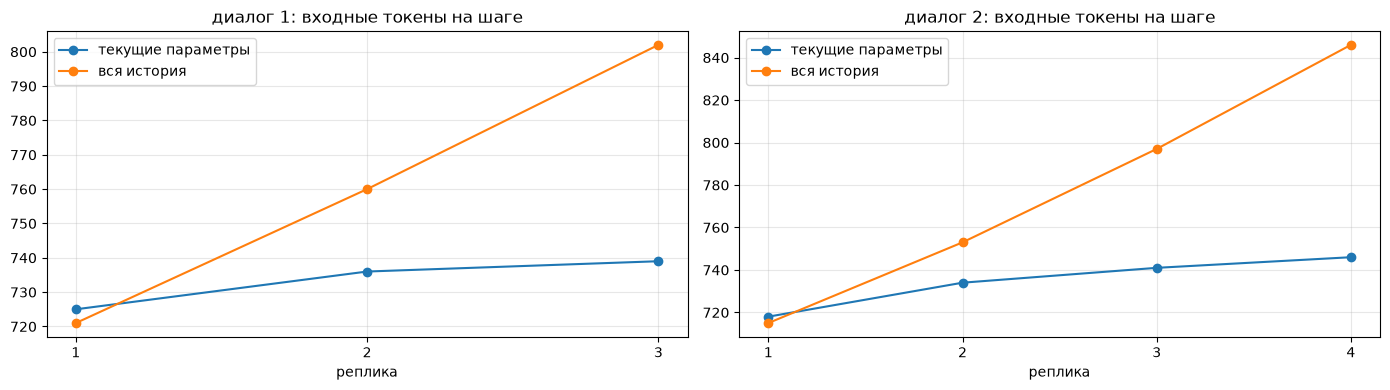

In [70]:
print(dlg_tab.groupby('dialog', sort=False)[['state_ok', 'hist_ok', 'state_tokens', 'hist_tokens']].sum())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (dname, d) in zip(axes, dlg_tab.groupby('dialog', sort=False)):
  ax.plot(d['step'], d['state_tokens'], 'o-', label='текущие параметры')
  ax.plot(d['step'], d['hist_tokens'], 'o-', label='вся история')
  ax.set_title(f'{dname}: входные токены на шаге')
  ax.set_xlabel('реплика')
  ax.set_xticks(d['step'])
  ax.grid(alpha=0.3)
  ax.legend()
plt.tight_layout()
plt.show()

In [71]:
DLG_JOURNALS['диалог 1'].show()

16:33:39.259 | req=1 | request        | запрос пользователя: 'Покажи ноутбуки до 80 тысяч'
16:33:39.266 | req=1 | llm_start      | вызов LLM, попытка 1
16:33:39.646 | req=1 | llm_end        | ответ за 0.37 с, токенов вход/выход: 725/36
16:33:39.649 | req=1 | parse_ok       | JSON разобран
16:33:39.653 | req=1 | validate_ok    | параметры прошли проверку ProductQuery: {"category":"laptop","max_price":80000,"sort_by":"price_asc"}
16:33:39.655 | req=1 | check          | категория поддерживается, параметры ок
16:33:39.657 | req=1 | search_start   | поиск в SQLite: laptop, 80000, price_asc
16:33:39.659 | req=1 | search_end     | найдено товаров: 5
16:33:39.662 | req=1 | done           | Найдено товаров: 5
16:33:40.070 | req=2 | request        | запрос пользователя: 'А сначала дорогие?'
16:33:40.073 | req=2 | llm_start      | вызов LLM, попытка 1
16:33:40.440 | req=2 | llm_end        | ответ за 0.36 с, токенов вход/выход: 736/36
16:33:40.443 | req=2 | parse_ok       | JSON разобран
16:33:40.

- с текущими параметрами все 7 шагов правильные, с полной историей 6 из 7: в диалоге 1 на "А что есть среди смартфонов?" вариант с историей вернул `smartphone, None, price_asc`, т.е. потерял и потолок 80 000, и сортировку "сначала дорогие". Вариант с состоянием на этом шаге сохранил `80000, price_desc`. Это как раз ожидаемая ошибка: по истории модели надо самой собрать параметры из нескольких реплик, а тут она восприняла смену категории как новый поиск
- входные токены с историей растут с каждой репликой: 721 -> 760 -> 802 и 715 -> 753 -> 797 -> 846 (+40-50 на шаг), а с состоянием почти стоят на месте: 725 -> 739 и 718 -> 746. Суммарно 2283 против 2200 и 3111 против 2939. На коротких диалогах разница небольшая, тк большую часть промпта (~700 токенов) занимают правила и инструкции формата, но история растёт без ограничений
- ещё плюс состояния в программе: его можно проверить, показать пользователю и сбросить (`/new` в `app.py`), а история — просто текст

## Итоговая программа

`app.py` собирает всё вместе: состояние диалога (5.1), пайплайн с retry и журналом, обработка `other`, пустых результатов, ответа без вызова инструмента и исчерпания попыток, подтверждение без цены.
```
python app.py              # диалог, параметры через инструкции формата
python app.py --tools      # параметры через вызов инструмента
python app.py --verbose    # печатать журнал
```
Команды: `/new` — новый поиск, `/log` — журнал последнего запроса, `/exit` — выход

In [72]:
!"{sys.executable}" app.py --no-confirm "Покажи самые дешевые ноутбуки до 80 тысяч рублей"

   (параметры: {"category":"laptop","max_price":80000,"sort_by":"price_asc"})
Найдено товаров: 5
  - Lenovo IdeaPad Slim 3 15 — 54 990 ₽
  - ASUS Vivobook 16 — 61 490 ₽
  - Acer Aspire 5 — 67 990 ₽
  - HUAWEI MateBook D 16 — 74 990 ₽
  - HONOR MagicBook X16 — 79 990 ₽


## Выводы

1. Пайплайн работает: LLM только интерпретирует запрос и возвращает `ProductQuery`, SQL и поиск делает обычный код с параметризованными запросами. На 12 тестовых запросах параметры разобраны правильно в 12 случаях, пустые результаты и неподдерживаемые категории обрабатываются отдельными сообщениями
2. Structured output получен двумя способами - инструкции формата + `PydanticOutputParser` и вызов инструмента; на запросах из 2.3 оба дали 5 из 5. Через инструменты модель может сделать несколько вызовов (для "ноут или планшет" - два), что одним JSON не выразить, но тогда выполнять надо все вызовы. Проверка по схеме Pydantic обязательна в обоих случаях
3. Без базы модель на все три вопроса ответила, что каталога не видит, и не назвала ни одного нашего товара — правильный список даёт только поиск по базе.
4. Ошибки разбора - синтаксические (`JSONDecodeError`) и ошибки схемы (`ValidationError`), обе приходят как `OutputParserException`. Настоящая модель на всех запросах отвечала с первой попытки, поэтому retry проверен на FakeListChatModel: "битый -> верный" проходит за 2 попытки с одним поиском, при 3 неудачах программа выдаёт понятное сообщение и в базу не идёт.
5. Режим размышления увеличивает время и выходные токены примерно в 10 раз при тех же параметрах. Сервер отдаёт рассуждение в отдельном поле `reasoning_content`, поэтому JSON в `content` разбирается без проблем; `ChatOpenAI` это поле теряет
6. Уточняющие запросы: с состоянием в программе 7 из 7 шагов правильно, с полной историей 6 из 7, а входные токены с историей растут на 40–50 на реплику
7. Ограничения схемы: нет бренда, нескольких категорий и "примерной" цены. Поэтому "Покажи что-нибудь от Apple подороже" превращается в `other` (такого нет), хотя в базе 5 товаров Apple во всех трёх категориях, а айфоны - во все 7 смартфонов. Следующий шаг - поле `brand` (фильтр `name LIKE ?`) и список категорий в `ProductQuery`, а в режиме инструмента - выполнение всех вызовов

## Контрольные вопросы

1. Пайплайн vs агент: у нас порядок шагов зашит в коде (LLM -> разбор -> проверка -> поиск -> вывод), модель не выбирает функцию и не видит результат. В агенте LLM сама решает, какие инструменты и в каком порядке вызывать, получает результаты и решает, что делать дальше
2. Цепочки собираются оператором `|` из Runnable (промпт, модель, парсер, `RunnableLambda`), выход одного является входом следующего. `StrOutputParser` достаёт из `AIMessage` только текст `content`
3. System/human: системное сообщение задает роль, правила и формат и не меняется от запроса к запросу, пользовательское - сам запрос. Так модель отделяет инструкции от данных, а шаблон легко параметризовать
4. Structured Output - ответ в заранее заданной структуре (JSON по схеме), который программа может разобрать и проверить. А произвольный текст программно так же надежно обработать не может
5. `BaseModel` - описание схемы и валидация, **`Field`** - описание поля, значение по умолчанию и ограничения (`ge=0`), **`Literal`** - допустимые значения
6. LLM без базы не знает содержимого конкретного каталога, цен и наличия - этого не было в обучении,  без базы она просто будет угадывать
7. Схема идёт отдельным полем `tools`, парсер вызовов на сервере вырезает вызов из сгенерированного текста и отдаёт структурированные `tool_calls`. За приложением остаётся проверить аргументы по схеме, выполнить действие и обработать случай без вызова. С инструкциями формата схема - это просто текст в промпте и весь разбор делает приложение
8. Валидация до ПО: модель может вернуть неверный тип, несуществующую категорию, отрицательную цену, и программа упадет или сделает что-то не то. SQL от LLM без ограничений исполнять нельзя, т.к. она может ошибиться или ее можно уговорить промпт-инъекцией написать `DROP TABLE` или выгрузить лишние данные. Поэтому SQL собирает код из белого списка, значения через параметры
9. Retry должен ловить ошибки разбора и валидации, т.е то, что может исправить повторная генерация. Сеть - это отдельная история, а `other` или пустой результат повторять бессмысленно. Повтор с тем же промптом просто надеется на другой ответ (при `temperature=0` его может и не быть), а исправление с учётом ошибки передаёт модели её ответ и текст ошибки (`RetryWithErrorOutputParser` / `OutputFixingParser`)
10. Состояние диалога храним в программе (последний валидный `ProductQuery`), а модели на каждом шаге передаем только его и новую реплику